# PTA stop context features

## Dataset, API and output at a glance

**Public Transport Authority Stops (PTA-001)** is the official point layer published by the Western Australian Public Transport Authority through Data WA. Each source record describes a public-transport stop and includes its identifier, source status, stop type and geographic point. This notebook uses the official **Data WA SLIP ArcGIS REST MapServer API**, layer 14 of `SLIP_Public_Services/Transport`. The layer endpoint supplies metadata and the `/query` endpoint supplies count-verified, ordered pages in `EPSG:4326`. It is not the Transperth GTFS timetable feed.

```text
https://public-services.slip.wa.gov.au/public/rest/services/SLIP_Public_Services/Transport/MapServer/14
```

The source can describe where active stops are, the type of the nearest stop and the number of active stop points nearby. It does not provide pedestrian counts, boardings, walking routes, live arrivals, reliability or verified service frequency. The reusable acquisition, validation, cleaning, projection, feature-construction, QA and safe-provenance logic has been promoted to `src/pedflow/context/sources/pta_stops.py`. This notebook remains the scientific explanation, diagnostic view and reviewed-output regression reference.

The three candidate model features are: `pta_nearest_active_stop_distance_m`, the straight-line projected distance to the nearest unique Active stop; `pta_nearest_active_stop_type`, the source category of that stop; and `pta_active_stops_within_500m`, the count of unique Active stop points on or within an inclusive 500 m radius. `site_id` is the join key, `pta_data_status` is a QA field, and `pta_nearest_stop_id` is an audit identifier rather than a predictor.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display


def find_project_root() -> Path:
    """Find the repository from common notebook launch locations."""
    current = Path.cwd().resolve()
    for path in [current, *current.parents]:
        if (path / "pyproject.toml").is_file() and (path / "data").is_dir():
            return path
    raise FileNotFoundError(
        f"Project root not found from {current}. Expected pyproject.toml and data/."
    )


PROJECT_ROOT = find_project_root()
SOURCE_DIRECTORY = PROJECT_ROOT / "src"
if str(SOURCE_DIRECTORY) not in sys.path:
    sys.path.insert(0, str(SOURCE_DIRECTORY))

from pedflow.context.contracts import SourceConfig
from pedflow.context.sources.pta_stops import (
    APPROVED_FEATURE_COLUMNS,
    acquire_or_load_source,
    extract,
    prepare_source,
    validate_source_specific,
)
from pedflow.context.validation import validate_and_normalise_sites

MODEL_DATASET_PATH = PROJECT_ROOT / "data" / "processed" / "model_dataset.xlsx"
FEATURE_OUTPUT_PATH = (
    PROJECT_ROOT
    / "06_outputs"
    / "02_feature_extraction"
    / "02_03_haoqi_pta_stops_features.xlsx"
)
SOURCE_SNAPSHOT_DATE = "2026-08-25"
BUFFER_RADIUS_M = 500.0
DISTANCE_REGRESSION_TOLERANCE_M = 0.1

if not MODEL_DATASET_PATH.is_file():
    raise FileNotFoundError(f"Required project file not found: {MODEL_DATASET_PATH}")
if not FEATURE_OUTPUT_PATH.is_file():
    raise FileNotFoundError(f"Reviewed regression output not found: {FEATURE_OUTPUT_PATH}")

print("Project root :", PROJECT_ROOT)
print("Model input  :", MODEL_DATASET_PATH.relative_to(PROJECT_ROOT))
print("Snapshot date:", SOURCE_SNAPSHOT_DATE)
print("Feature file :", FEATURE_OUTPUT_PATH.relative_to(PROJECT_ROOT))

Project root : /workspace
Model input  : data/processed/model_dataset.xlsx
Snapshot date: 2026-08-25
Feature file : 06_outputs/02_feature_extraction/02_03_haoqi_pta_stops_features.xlsx


## 1. Read the authoritative model sites

The notebook reads `Model_Data` only to obtain the shared site input. The reusable PTA module receives the already validated `sites` DataFrame and does not reopen the workbook. The common contract retains exactly `site_id`, `latitude`, `longitude` and `coordinate_crs`, requires unique non-blank identifiers and WGS84 coordinates, and does not expose pedestrian targets to the source adapter. No row-count assumption is made.

In [2]:
model_data = pd.read_excel(
    MODEL_DATASET_PATH,
    sheet_name="Model_Data",
    dtype={"site_id": "string", "coordinate_crs": "string"},
)
sites = validate_and_normalise_sites(model_data)

print(f"Input sites: {len(sites):,}")
print(f"Unique site_id values: {sites['site_id'].nunique():,}")
display(sites.head())

Input sites: 49
Unique site_id values: 49


,site_id,latitude,longitude,coordinate_crs
0,250303-01,-32.866282,115.705163,EPSG:4326
1,250303-02,-33.359642,115.678041,EPSG:4326
2,250303-03,-33.360624,116.154738,EPSG:4326
3,250303-04,-34.238746,116.149491,EPSG:4326
4,250303-05,-32.628918,115.874612,EPSG:4326


## 2. Load and inspect the reviewed PTA snapshot

The adapter supports count-verified ArcGIS retrieval with controlled GET retries, timeouts and atomic dated caching. This reviewed notebook deliberately freezes the `2026-08-25` cache and disables network download so its regression result cannot drift with a later live layer. Source validation checks the GeoJSON schema, required attributes, point geometry, Active-stop coordinates, exact duplicate rows and conflicting repeated `stopid` records. Planned stops and ungeocoded records are not used as Active accessibility.

In [3]:
pta_config = SourceConfig(
    name="pta_stops",
    enabled=True,
    options={
        "snapshot_date": SOURCE_SNAPSHOT_DATE,
        "cache_directory": "data/external_raw/pta_stops",
        "allow_download": False,
        "buffer_radius_m": BUFFER_RADIUS_M,
        "timeout_seconds": 120,
        "retry_count": 4,
    },
)
snapshot = acquire_or_load_source(pta_config, PROJECT_ROOT)
prepared_source = prepare_source(snapshot.feature_collection)

print(f"Snapshot source: {snapshot.retrieval_method}")
print(f"Layer name: {snapshot.layer_metadata.get('name')}")
print(f"Snapshot records: {len(prepared_source.all_stops):,}")
print(
    "Exact duplicate source rows excluded from analysis:",
    f"{prepared_source.exact_duplicate_count:,}",
)
print(f"Unique geocoded active stops used: {len(prepared_source.active_stops):,}")
display(pd.Series(prepared_source.status_counts, name="records").to_frame())
display(
    pd.Series(
        prepared_source.active_stop_type_counts, name="active_stops"
    ).to_frame()
)
display(
    prepared_source.active_stops[["accessible", "shelter"]]
    .value_counts(dropna=False)
    .rename("active_stops")
    .to_frame()
)

Snapshot source: cached
Layer name: Public Transport Authority Stops (PTA-001)
Snapshot records: 16,813
Exact duplicate source rows excluded from analysis: 7
Unique geocoded active stops used: 16,795


,records
Active,16802
Planned,11


,active_stops
Standard,13829
School,2264
Transwa,325
Rail,188
Standard\CAT,119
CAT,68
Ferry,2


,,active_stops
accessible,shelter,
Y,Y,16795


## 3. Build the promoted site-level features

The adapter assigns each valid WA site to its local WGS84 UTM zone, projects all Active stops into that metre-based CRS, calculates Euclidean distances, selects the nearest stop and counts distances `<= 500 m`. A valid site with no stop in the radius keeps its real nearest distance and receives `valid_no_stop_within_500m`; no artificial maximum distance is imposed. The returned `FeatureResult` contains one row per supplied `site_id`, only approved `pta_` columns, a snapshot/hash source version, safe metadata and non-secret warnings.

In [4]:
pta_result = extract(sites, pta_config, PROJECT_ROOT)
features = pta_result.features.copy()

if pta_result.metadata["geojson_sha256"] != snapshot.geojson_sha256:
    raise ValueError("Adapter and notebook diagnostics used different PTA snapshots.")

print("Source version:", pta_result.source_version)
print("Warnings:", list(pta_result.warnings) or "None")
display(features.head(10))

Source version: PTA-001-2026-08-25-d84200bfa5d0
Warnings: ['Excluded 7 exact duplicate source rows from analysis.']


,site_id,pta_data_status,pta_nearest_active_stop_distance_m,pta_nearest_active_stop_type,pta_active_stops_within_500m,pta_nearest_stop_id
0,250303-01,valid_no_stop_within_500m,9163.3,Transwa,0,28638
1,250303-02,valid_no_stop_within_500m,564.3,Transwa,0,45001
2,250303-03,matched,265.0,School,4,38037
3,250303-04,matched,93.5,School,11,36961
4,250303-05,matched,182.2,Standard,13,45419
5,250303-06,valid_no_stop_within_500m,788.8,Transwa,0,45298
6,250303-07,matched,71.3,Transwa,1,28678
7,250303-08,matched,231.3,Transwa,2,28782
8,250303-09,matched,210.6,Transwa,1,45259
9,250303-10,matched,315.7,School,4,43205


## 4. Source-specific QA and scientific diagnostics

The promoted QA checks approved schema and exact site coverage, unique keys, allowed statuses, non-negative distances and integer counts, nearest-stop audit fields for valid sites, missing values for invalid-coordinate rows, and exact agreement between zero counts and `valid_no_stop_within_500m`. The notebook retains distribution plots and shortest/longest matches for scientific review; plots and `display` are intentionally absent from the module. Regional long distances are not automatically removed and should be interpreted with remoteness context.

PTA feature status:


,sites
pta_data_status,
matched,34
valid_no_stop_within_500m,15


Nearest active stop type:


,sites
pta_nearest_active_stop_type,
Transwa,28
Standard,11
School,10


,pta_nearest_active_stop_distance_m,pta_active_stops_within_500m
count,49.000000,49.0
mean,12473.412245,3.44898
std,55312.159921,4.532573
min,8.600000,0.0
25%,114.900000,0.0
50%,231.300000,1.0
75%,788.800000,5.0
90%,3338.100000,11.0
max,352550.000000,17.0


Shortest-distance checks:


,site_id,latitude,longitude,pta_nearest_active_stop_distance_m,pta_nearest_active_stop_type,pta_nearest_stop_id
11,250303-12,-34.314900,115.159261,8.6,Transwa,28743
43,260335-47,-33.309062,117.344776,9.0,Transwa,28628
25,260335-29,-30.761932,121.456695,12.6,School,29173
15,250303-16,-32.628933,115.872394,30.3,Standard,45419
29,260335-33,-34.993578,117.857386,32.0,Standard,43514


Longest-distance checks:


,site_id,latitude,longitude,pta_nearest_active_stop_distance_m,pta_nearest_active_stop_type,pta_nearest_stop_id
20,250341-04,-18.196519,125.565875,352550.0,Standard,47622
19,250341-03,-17.305548,123.633717,162908.2,School,43031
46,260335-50,-30.275920,116.663871,58253.3,Transwa,29004
24,260335-28,-30.954671,121.162305,12496.5,Transwa,29305
0,250303-01,-32.866282,115.705163,9163.3,Transwa,28638


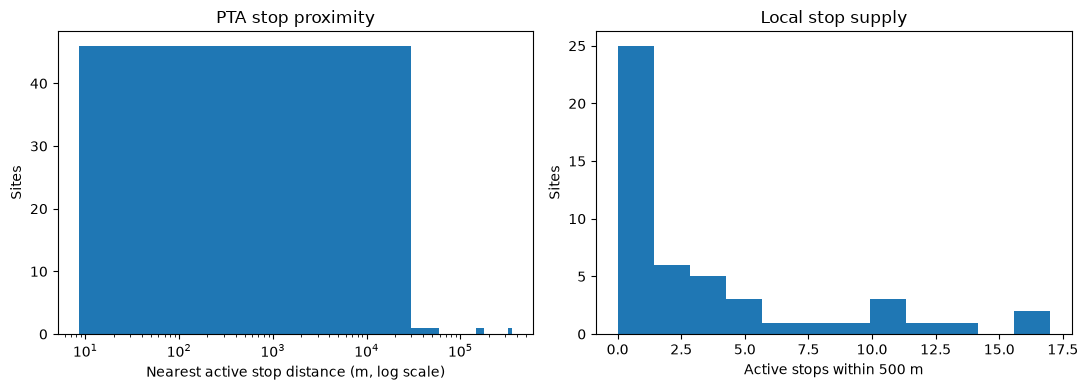

In [5]:
validate_source_specific(features, sites)
diagnostic = sites[["site_id", "latitude", "longitude"]].merge(
    features, on="site_id", how="left", validate="one_to_one"
)
valid_diagnostic = diagnostic.loc[
    diagnostic["pta_data_status"].ne("invalid_coordinate")
].copy()

print("PTA feature status:")
display(features["pta_data_status"].value_counts(dropna=False).to_frame("sites"))
print("Nearest active stop type:")
display(
    features["pta_nearest_active_stop_type"]
    .value_counts(dropna=False)
    .to_frame("sites")
)
display(
    valid_diagnostic[
        ["pta_nearest_active_stop_distance_m", "pta_active_stops_within_500m"]
    ].describe(percentiles=[0.25, 0.5, 0.75, 0.9])
)
audit_columns = [
    "site_id",
    "latitude",
    "longitude",
    "pta_nearest_active_stop_distance_m",
    "pta_nearest_active_stop_type",
    "pta_nearest_stop_id",
]
print("Shortest-distance checks:")
display(valid_diagnostic.nsmallest(5, "pta_nearest_active_stop_distance_m")[audit_columns])
print("Longest-distance checks:")
display(valid_diagnostic.nlargest(5, "pta_nearest_active_stop_distance_m")[audit_columns])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(valid_diagnostic["pta_nearest_active_stop_distance_m"], bins=12)
axes[0].set_xscale("log")
axes[0].set_xlabel("Nearest active stop distance (m, log scale)")
axes[0].set_ylabel("Sites")
axes[0].set_title("PTA stop proximity")
axes[1].hist(valid_diagnostic["pta_active_stops_within_500m"], bins=12)
axes[1].set_xlabel("Active stops within 500 m")
axes[1].set_ylabel("Sites")
axes[1].set_title("Local stop supply")
plt.tight_layout()
plt.show()

## 5. Confirm the reviewed result, save the independent table and demonstrate merge

The promoted output is compared with the reviewed workbook without rewriting that baseline. Identifiers, categories, statuses and counts must match exactly. Distance uses an absolute tolerance of 0.1 m and zero relative tolerance because the published feature is rounded to 0.1 m; this allows at most one displayed unit of projection-library variation while remaining negligible relative to the 500 m threshold. The final example merges the validated in-memory features by `site_id`; if the current foundation table contains `qa_status`, the training demonstration then applies `qa_status == 'ready'`, otherwise it explicitly skips that optional step. It does not write either the reviewed workbook or the integrated workflow output.

In [6]:
reviewed_features = pd.read_excel(
    FEATURE_OUTPUT_PATH,
    sheet_name="PTA_Stop_Features",
    dtype={"site_id": "string", "pta_nearest_stop_id": "string"},
)
if list(reviewed_features.columns) != list(APPROVED_FEATURE_COLUMNS):
    raise ValueError("Reviewed PTA workbook does not have the approved schema.")

exact_columns = [
    "site_id",
    "pta_data_status",
    "pta_nearest_active_stop_type",
    "pta_active_stops_within_500m",
    "pta_nearest_stop_id",
]
for column in exact_columns:
    pd.testing.assert_series_equal(
        features[column].reset_index(drop=True),
        reviewed_features[column].reset_index(drop=True),
        check_dtype=False,
        check_names=True,
    )
np.testing.assert_allclose(
    features["pta_nearest_active_stop_distance_m"].to_numpy(dtype=float),
    reviewed_features["pta_nearest_active_stop_distance_m"].to_numpy(dtype=float),
    rtol=0.0,
    atol=DISTANCE_REGRESSION_TOLERANCE_M,
    equal_nan=True,
)
print("Reviewed-output regression check passed.")

saved_features = features.copy()
modeling_df = model_data.merge(
    saved_features, on="site_id", how="left", validate="one_to_one"
)
if "qa_status" in modeling_df.columns:
    training_df = modeling_df.loc[modeling_df["qa_status"].eq("ready")].copy()
    training_message = f"Training rows after qa_status filter: {len(training_df):,}"
else:
    training_df = None
    training_message = "qa_status is not present; optional training filter skipped."

print(f"Validated feature rows: {len(saved_features):,}")
print(f"Merged modelling rows: {len(modeling_df):,}")
print(training_message)
print("Reviewed output unchanged:", FEATURE_OUTPUT_PATH.relative_to(PROJECT_ROOT))
display(saved_features.head())

Reviewed-output regression check passed.
Validated feature rows: 49
Merged modelling rows: 49
qa_status is not present; optional training filter skipped.
Reviewed output unchanged: 06_outputs/02_feature_extraction/02_03_haoqi_pta_stops_features.xlsx


,site_id,pta_data_status,pta_nearest_active_stop_distance_m,pta_nearest_active_stop_type,pta_active_stops_within_500m,pta_nearest_stop_id
0,250303-01,valid_no_stop_within_500m,9163.3,Transwa,0,28638
1,250303-02,valid_no_stop_within_500m,564.3,Transwa,0,45001
2,250303-03,matched,265.0,School,4,38037
3,250303-04,matched,93.5,School,11,36961
4,250303-05,matched,182.2,Standard,13,45419
